# Daily births: how much history should a forecast learn from?

**A forecaster of daily births learns three things from the past: the level, the week and the season. Learning the week from all the history there is misses by 28% more than learning it from the last year, because the week itself changed over these twenty years. The season is the other way around: one year of it is 12% worse than three, and seven are as good as three. So each part has its own answer to "how much history", and the two ends of the scale, everything and the last year only, are the costly ones. A generated week with a change at a known date shows the same turn where the truth is known, and shows that with nothing changing, more history only helps. With look-backs that fit, the forecast misses by 1.6% a week ahead and 2.1% thirteen weeks ahead.**

A maternity ward draws up its roster weeks ahead, and the number it needs is how many births to expect on each day. Births follow a week, a season and a slowly moving level, and a forecaster has to learn each of them from the past. How much of the past? "All of it" sounds safe. This notebook runs the same forecaster with different look-backs on the same test days, and then repeats the test on a generated series where we know what changed and when.

*Data: births in the United States on each day from 1969 to 1988, from the R package mosaicData ([source and license](data/README.md#us-births)). The whole country stands in for a ward: the counts are large, so what is left over after the forecast is small. To run this notebook yourself, see [Run an example yourself](../docs/examples.md#run-an-example-yourself).*

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from pandas.tseries.holiday import USFederalHolidayCalendar

from timegym import Pipeline, Scenario, cases_from_series
from timegym.statistics import paired_t_interval

from example_data import load  # examples/example_data.py, next to this notebook

plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})

## A week that changed

Fewer babies are born on weekends, because planned deliveries are booked on working days. Over these twenty years that gap widened, year after year.

Public holidays, the days from 23 December to 2 January and the Friday after Thanksgiving are left out of everything below, both the scoring and what the forecaster learns about the week. They need a calendar of their own, which [Tomorrow's electricity demand](electricity-demand.ipynb) builds.

7,305 days, 01 January 1969 to 31 December 1988; 383 left out as holidays
Births a day: 9,649 on average
A Saturday as a share of a working day: 91% in 1969, 81% in 1988
A Sunday as a share of a working day:   85% in 1969, 77% in 1988


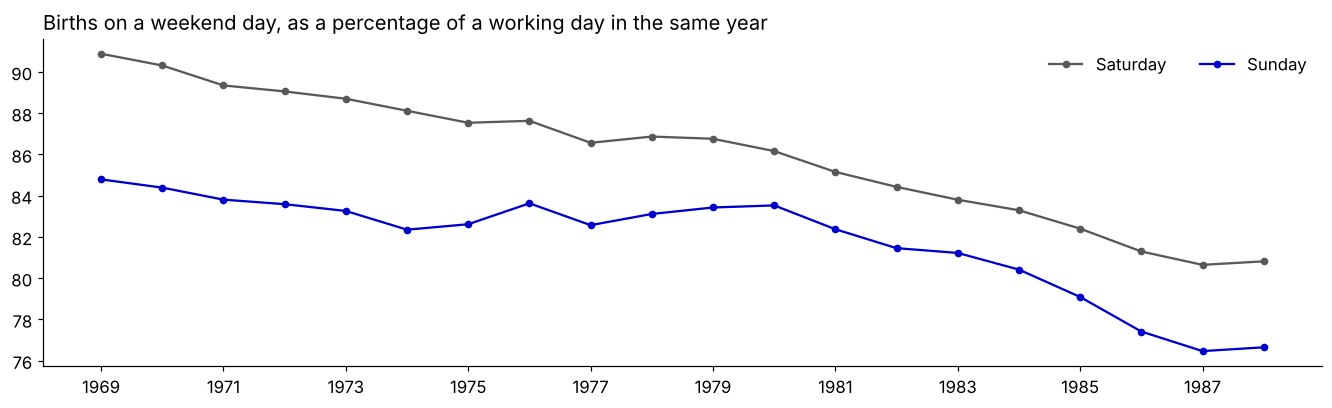

In [2]:
births = load("us-births")
days = births.index
values = births["births"].to_numpy(float)

public = USFederalHolidayCalendar().holidays(days[0], days[-1])
year_end = ((days.month == 12) & (days.day >= 23)) | ((days.month == 1) & (days.day <= 2))
after_thanksgiving = (days.month == 11) & (days.day_of_week == 4) & (days.day >= 23) & (days.day <= 29)
special = np.asarray(days.isin(public) | year_end | after_thanksgiving)

ordinary = births["births"][~special]
by_day = ordinary.groupby([ordinary.index.year, ordinary.index.day_of_week]).mean().unstack()
working_day = by_day[[0, 1, 2, 3, 4]].mean(axis=1)
saturday, sunday = by_day[5] / working_day * 100, by_day[6] / working_day * 100

print(f"{len(days):,} days, {days[0]:%d %B %Y} to {days[-1]:%d %B %Y}; {special.sum()} left out as holidays")
print(f"Births a day: {values.mean():,.0f} on average")
print(f"A Saturday as a share of a working day: {saturday[1969]:.0f}% in 1969, {saturday[1988]:.0f}% in 1988")
print(f"A Sunday as a share of a working day:   {sunday[1969]:.0f}% in 1969, {sunday[1988]:.0f}% in 1988")

fig, ax = plt.subplots(figsize=(12, 3.6), layout="constrained")
ax.plot(saturday.index, saturday, color="0.35", marker="o", markersize=4, label="Saturday")
ax.plot(sunday.index, sunday, color="#0000CC", marker="o", markersize=4, label="Sunday")
ax.set_title("Births on a weekend day, as a percentage of a working day in the same year")
ax.set_xticks(range(1969, 1989, 2))
ax.legend(loc="upper right", ncols=2)
plt.show()

assert len(days) == 7305 and days.freqstr == "D"
assert round(sunday[1969]) == 85 and round(sunday[1988]) == 77
assert round(saturday[1969]) == 91 and round(saturday[1988]) == 81

## The forecaster and its three look-backs

The roster is drawn up four weeks ahead, so the forecast that counts is the one for days 29 to 35. The forecaster has three parts, and each one looks back over a stretch of history.

- **The level**: the average of the last four weeks.
- **The week**: a factor for each day of the week, learned from the last `shape_days` days.
- **The season**: how births around the target date stood to births four weeks before today's date, averaged over the last `season_years` years.

A forecast is the three multiplied together. Every other week from January 1976 on, the forecaster is handed all the history up to that day and forecasts the next 13 weeks. All its versions get the same test days. The miss is a percentage of the births that came.

In [3]:
WEEK, LEVEL_DAYS, YEAR = 7, 28, 365


class Roster:
    def __init__(self, shape_days, season_years, special=None):
        self.shape_days = shape_days          # how far back the week is learned from
        self.season_years = season_years      # how many earlier years the season is learned from
        self.special = special                # True on holidays, counted from the first day of the series

    def fit(self, history):
        values = np.asarray(history, dtype=float).ravel()
        count = len(values)
        special = np.zeros(count, bool) if self.special is None else self.special[:count]
        start = max(0, count - self.shape_days)
        start += (count - start) % WEEK                                   # whole weeks only
        day = np.arange(start, count) % WEEK
        usable = ~special[start:]
        week = np.array([values[start:][(day == which) & usable].mean() for which in range(WEEK)])
        self.week_ = week / week.mean()
        self.level_ = values[-LEVEL_DAYS:].mean()
        self.sums_ = np.concatenate([[0.0], np.cumsum(values)])
        self.count_ = count
        return self

    def _average(self, first, last):
        return (self.sums_[last] - self.sums_[first]) / (last - first)       # the average of rows first..last-1

    def predict(self, dates):
        target = self.count_ + np.arange(len(dates))
        ratios = []
        for back in range(1, self.season_years + 1):
            today, then = self.count_ - YEAR * back, target - YEAR * back
            if today - LEVEL_DAYS >= 0:
                ratios.append(self._average(then - 3, then + 4) / self._average(today - LEVEL_DAYS, today))
        season = np.mean(ratios, axis=0) if ratios else 1.0
        return self.level_ * self.week_[target % WEEK] * season


AHEAD = 13 * WEEK
first = days.get_loc(pd.Timestamp("1976-01-01"))
origins = list(range(first, len(days) - AHEAD, 2 * WEEK))
cases = cases_from_series(births, origins, horizon=AHEAD, name="births")
actual = np.array([values[origin:origin + AHEAD] for origin in origins])
scored = np.array([~special[origin:origin + AHEAD] for origin in origins])
ROSTER_WEEK = slice(4 * WEEK, 5 * WEEK)          # days 29 to 35


def run(shape_days, season_years):
    # The miss of every forecast, as a percentage of the births that came: case by day ahead.
    result = Pipeline(Roster(shape_days, season_years, special)).run(cases=cases, keep_data=True)
    result.assert_passed()   # stop here if any forecast crashed or failed a check
    forecast = np.array([entry.forecast.point[:, 0] for entry in result.cases])
    return np.abs(forecast - actual) / actual * 100


def miss(table, days_ahead=ROSTER_WEEK):
    return float(table[:, days_ahead][scored[:, days_ahead]].mean())


print(f"{len(cases)} forecasts, made from {days[origins[0]]:%d %B %Y} to {days[origins[-1]]:%d %B %Y}")

333 forecasts, made from 01 January 1976 to 22 September 1988


## How far back for the week, and for the season?

First the week. The season is held at three years while the week is learned from the last 8 weeks, 26 weeks, 1 year, 2, 4 and 7 years, and from all the history there is, which is 7 years at the first forecast and 19 at the last.

Then the season, with the week held at one year: no season at all, then 1, 3 and 7 years.

The week from,8 weeks,26 weeks,1 year,2 years,4 years,7 years,All
Miss (%),1.92,1.82,1.8,1.82,1.88,2.0,2.31


The season from,None,1 year,3 years,7 years
Miss (%),3.39,2.02,1.8,1.81


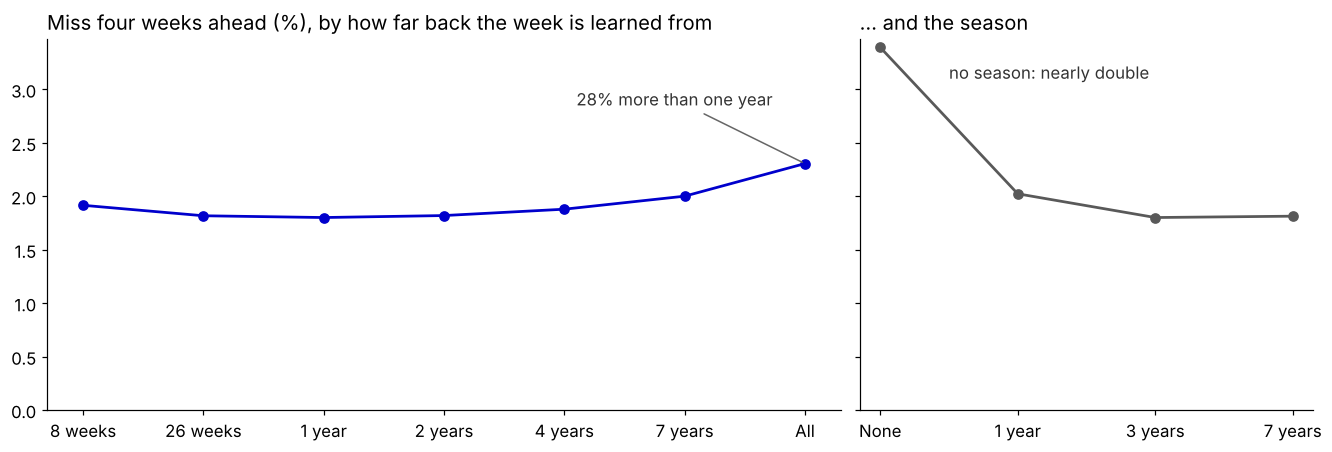

The week from all history against one year: +28% (+24 to +32)
The week from 8 weeks against one year:     +6% (+5 to +8)
The season from 1 year against 3 years:     +12% (+8 to +16)


One look-back for both,1 year,3 years,7 years,All
Miss (%),2.02,1.84,2.01,2.39


In [4]:
ALL = 10 ** 6
week_spans = {"8 weeks": 56, "26 weeks": 182, "1 year": 364, "2 years": 728,
              "4 years": 1456, "7 years": 2548, "All": ALL}
season_spans = {"None": 0, "1 year": 1, "3 years": 3, "7 years": 7}

by_week = {name: run(span, 3) for name, span in week_spans.items()}
by_season = {name: run(364, years) for name, years in season_spans.items() if years != 3}
by_season["3 years"] = by_week["1 year"]
week_miss = pd.Series({name: miss(table) for name, table in by_week.items()})
season_miss = pd.Series({name: miss(by_season[name]) for name in season_spans})

display(week_miss.round(2).to_frame("Miss (%)").rename_axis("The week from").T)
display(season_miss.round(2).to_frame("Miss (%)").rename_axis("The season from").T)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained", sharey=True,
                         gridspec_kw={"width_ratios": [7, 4]})
axes[0].plot(week_miss.index, week_miss, color="#0000CC", marker="o", linewidth=1.8)
axes[0].set_title("Miss four weeks ahead (%), by how far back the week is learned from")
axes[1].plot(season_miss.index, season_miss, color="0.35", marker="o", linewidth=1.8)
axes[1].set_title("... and the season")
axes[0].set_ylim(0, None)
axes[0].annotate("28% more than one year", (6, week_miss["All"]), xytext=(4.1, 2.85),
                 arrowprops={"arrowstyle": "-", "color": "0.4"}, color="0.2")
axes[1].annotate("no season: nearly double", (0, season_miss["None"]), xytext=(0.5, 3.1), color="0.2")
plt.show()


def more(first, second, tables):
    # How much larger the first miss is than the second, in percent, with an interval over forecasts.
    counted = scored[:, ROSTER_WEEK]
    some = counted.any(axis=1)                       # a week of nothing but holidays has no miss

    def each(table):
        return (table[:, ROSTER_WEEK] * counted)[some].sum(axis=1) / counted[some].sum(axis=1)

    found = paired_t_interval(each(tables[first]) - each(tables[second]))
    base = miss(tables[second])
    return found["mean"] / base * 100, [end / base * 100 for end in found["ci95"]]


stale, (stale_low, stale_high) = more("All", "1 year", by_week)
short, (short_low, short_high) = more("8 weeks", "1 year", by_week)
thin, (thin_low, thin_high) = more("1 year", "3 years", by_season)
print(f"The week from all history against one year: {stale:+.0f}% ({stale_low:+.0f} to {stale_high:+.0f})")
print(f"The week from 8 weeks against one year:     {short:+.0f}% ({short_low:+.0f} to {short_high:+.0f})")
print(f"The season from 1 year against 3 years:     {thin:+.0f}% ({thin_low:+.0f} to {thin_high:+.0f})")

one_window = pd.Series({"1 year": miss(by_season["1 year"]), "3 years": miss(run(3 * 364, 3)),
                        "7 years": miss(run(7 * 364, 7)), "All": miss(run(ALL, 19))})
display(one_window.round(2).to_frame("Miss (%)").rename_axis("One look-back for both").T)

assert week_miss.round(2).tolist() == [1.92, 1.82, 1.80, 1.82, 1.88, 2.00, 2.31]
assert season_miss.round(2).tolist() == [3.39, 2.02, 1.80, 1.81]
assert round(stale) == 28 and stale_low > 20 and round(short) == 6 and short_low > 0
assert round(thin) == 12 and thin_low > 5
assert one_window["3 years"] < 1.9 and one_window["All"] > 2.25

The week has a best look-back, around one year, where the miss is 1.80%. Shorter is a little worse: eight weeks give 6% more miss, because eight Sundays are few to average over. Longer is worse too, and all the history is 28% worse, with an interval from 24% to 32%. The forecaster that uses everything is forecasting with the week of the early 1970s.

The season goes the other way. Without it the miss nearly doubles. One year of it is 12% worse than three, since one year's season carries that year's accidents, and seven years are as good as three. The season did not move the way the week did.

The last table gives the forecaster one look-back for both parts, which is how a "training window" is usually set. Three years is a fair middle. The two ends, the last year only and everything there is, are where the cost is.

## Is it the data, or the method? A week with a known change

The reading above is that the week changed, so old years teach the wrong week. There is another possible reading: something in the method makes long look-backs worse. A generated series can tell the two apart, because we choose what happens in it.

`Scenario` makes a weekly cycle around a flat level, seven years long, twice: once with a week that never changes, and once with a week whose swing grows by 40% a year before the end. The same `Roster` class forecasts both four weeks ahead with five look-backs, and the miss is measured against the true cycle, which the generated series comes with.

In [5]:
SERIES = 100
steady = {"intercept": 100.0, "slope": 0.0, "amplitude": 10.0, "period": 7.0,
          "sigma": 4.0, "residual": "white_noise"}
changed = dict(steady, change_point=7 * 364 - 364, changes={"amplitude": 14.0})
control_spans = {name: week_spans[name] for name in ["8 weeks", "1 year", "2 years", "4 years", "7 years"]}


def true_miss(recipe, shape_days):
    scenario = Scenario("composite", history_length=7 * 364, horizon=5 * WEEK, parameters=recipe)
    result = Pipeline(Roster(shape_days, 0)).run(scenarios=[scenario], instances=SERIES, keep_data=True)
    assert len({entry.manifest["seed"] for entry in result.cases}) == SERIES
    gaps = [np.abs(entry.forecast.point[ROSTER_WEEK, 0] - entry.reference.mean[ROSTER_WEEK, 0])
            for entry in result.cases]
    return float(np.mean(gaps))


control = pd.DataFrame({name: {"A week that never changes": true_miss(steady, span),
                               "A week that grew a year ago": true_miss(changed, span)}
                        for name, span in control_spans.items()})
display(control.round(2).rename_axis("Miss against the true cycle"))

never, grew = control.loc["A week that never changes"], control.loc["A week that grew a year ago"]
assert never.is_monotonic_decreasing and round(never["8 weeks"], 2) == 1.20 and round(never["7 years"], 2) == 0.64
assert grew.round(2).tolist() == [1.20, 0.75, 1.41, 2.00, 2.25]

,8 weeks,1 year,2 years,4 years,7 years
Miss against the true cycle,,,,,
A week that never changes,1.2,0.75,0.69,0.66,0.64
A week that grew a year ago,1.2,0.75,1.41,2.00,2.25


Where the week never changes, more history only helps: the miss falls from 1.20 with eight weeks to 0.64 with seven years. Nothing in the method punishes a long look-back. Where the week grew a year before the end, one year still gives 0.75, and every look-back that reaches past the change is worse: 1.41, 2.00 and 2.25. Eight weeks cost the same 1.20 in both series, the price of never having to care.

On the real births the change came gradually over twenty years, so the turn is gentler. It is the same turn.

## How far ahead is the forecast worth acting on?

Every forecast above ran 13 weeks ahead, so the same runs say how the miss grows with the lead. This is the version with the week from one year and the season from three.

In [6]:
best = by_week["1 year"]
by_lead = pd.Series({week + 1: miss(best, slice(week * WEEK, (week + 1) * WEEK)) for week in range(13)})
flat = pd.Series({week + 1: miss(by_season["None"], slice(week * WEEK, (week + 1) * WEEK))
                  for week in range(13)})
shown = [1, 2, 4, 8, 13]
display(pd.DataFrame({"With the season": by_lead, "Without the season": flat}).loc[shown].round(2)
        .rename_axis("Weeks ahead").T)

assert by_lead.round(2)[1] == 1.58 and by_lead.round(2)[13] == 2.07
assert flat.round(2)[1] == 2.15 and flat.round(2)[13] == 4.96

Weeks ahead,1,2,4,8,13
With the season,1.58,1.62,1.73,1.90,2.07
Without the season,2.15,2.51,3.12,4.19,4.96


With the season, the miss grows from 1.58% one week ahead to 2.07% thirteen weeks ahead. A roster drawn up three months ahead gives up about a third of the accuracy of one drawn up for next week, which for many plans is a fair price. Without the season the miss more than doubles over the same stretch. What keeps the far forecast worth acting on is the part that needs the long look-back.

## What TimeGym added

- **The same test days for every version.** `cases_from_series` cut 333 forecasts once. Each case hands the forecaster all the history up to its day, and the look-back is the forecaster's own choice, two arguments of one class. Thirteen versions ran on the same cases.
- **Thirteen weeks from one run.** Every forecast is kept, so the roster week, the table by weeks ahead and the intervals were all worked out after the runs.
- **A change at a known date.** `Scenario` made a weekly cycle with and without a change, and came with the true cycle to score against. That separated "long look-backs are bad" from "long look-backs are bad when something changed".
- **Intervals over forecasts.** `paired_t_interval` put a range on each comparison.

## Change one thing

- Give the level a look-back to test: `LEVEL_DAYS = 7`, then 91.
- Move the change in the generated week to three years before the end. Where does the best look-back go?
- Keep all the history for the week and weight each year by how recent it is. Can that beat one year?
- In this data, births on a Friday the 13th run about 3% below other Fridays. Add those days to `special` and see whether anything moves.
- Start the test in 1972, when there are only three years of history. Which look-backs can you still compare?

**What this doesn't show.** These are the births of a whole country, about 9,600 a day. A ward with ten births a day has chance on top that swamps most of what is measured here; the order of the look-backs would be the same and the differences much harder to see. No version models the change itself. A forecaster that followed the weekend's slide and carried it forward could beat every look-back. Holidays are left out, 383 days of 7,305. The forecasts are made two weeks apart and each runs 13 weeks, so neighbors share most of their days and the intervals are too narrow. The data ends in 1988.

**Related:** [The Christmas order](christmas-order.ipynb) has a line that gets worse with every year of history it is given, for a related reason. [Site capacity](site-capacity.ipynb) tests forecasts at the lead time they are used at. [Tomorrow's electricity demand](electricity-demand.ipynb) deals with the holidays left out here. [Real-data forecasts](../tutorials/07_real_data_forecasts.ipynb) covers `cases_from_series`. More examples are on the [examples page](../docs/examples.md).